In [56]:
import sys
sys.path.append('../scripts')
from utils.cftp_func import *
import glob
from scipy.stats import linregress

In [57]:
julia_colors = [
    '#00A9AD',  # teal
    '#E28F41',  # orange
    '#389826',  # green
    '#9558B2',  # purple
    '#BB7DC0',  # light purple
    '#CB3C33',  # red
    '#7C7C7C',  # grey
    '#4063D8',  # blue
]
from cycler import cycler
plt.rcParams['axes.prop_cycle'] = cycler(color=julia_colors)
plt.rcParams['axes.spines.top'] = False
plt.rcParams['axes.spines.right'] = False
plt.rcParams['legend.frameon'] = False

plt.rcParams['font.size'] = 14          # base size, everything scales from this
plt.rcParams['axes.labelsize'] = 16     # x/y axis labels
plt.rcParams['xtick.labelsize'] = 13
plt.rcParams['ytick.labelsize'] = 13
plt.rcParams['legend.fontsize'] = 12
plt.rcParams['axes.titlesize'] = 16

In [58]:
graph_type = 'EA2D'
coup_type = 'ising'
d = 2
if graph_type == 'ER' and coup_type == 'ising':
    beta_SG = np.arctanh(np.sqrt(1/d))
    beta_uni = np.arctanh(1/d)
    print(f"beta_uni = {beta_uni:.6f}, beta_SG = {beta_SG:.6f}")
elif graph_type == 'ER' and coup_type == 'gauss':
    beta_uni = solve_beta_critical_gauss(d=4)
    print(f"beta_uni = {beta_uni:.6f}")
elif graph_type == 'RR' and coup_type == 'ising':
    beta_SG = np.arctanh(np.sqrt(1/(d-1)))
    beta_uni = np.arctanh(1/(d-1))
    beta_dob = np.arctanh(1/d)
    print(f"beta_dob = {beta_dob:.6f}, beta_uni = {beta_uni:.6f}, beta_SG = {beta_SG:.6f}")
elif graph_type == 'EA2D' and coup_type == 'ising':
    beta_uni = np.arctanh(1/3)
    print(f"beta_uni = {beta_uni:.6f}")
elif graph_type == 'EA3D' and coup_type == 'ising':
    beta_uni = np.arctanh(1/5)
    print(f"beta_uni = {beta_uni:.6f}")


beta_uni = 0.346574


In [59]:
if graph_type == 'ER' and coup_type in ('ising', 'gauss'):
    folder_data = f"perm/{graph_type}_{coup_type}"
else:
    folder_data = "tmp"
dfs = [pd.read_csv(f) for f in glob.glob(f'../results/{folder_data}/coal_time_{graph_type}_{coup_type}_d{d}_beta*.csv')]
df = pd.concat(dfs, ignore_index=True)
if graph_type in ('EA2D', 'F2D'):
    print("betas:", sorted(df['beta'].unique()), "\nL:", sorted(df['N'].unique()), "\nsizes:", sorted(df['N'].unique()**2))
elif graph_type in ('EA3D', 'F3D'):
    print("betas:", sorted(df['beta'].unique()), "\nL:", sorted(df['N'].unique()), "\nsizes:", sorted(df['N'].unique()**3))
else:
    print("betas:", sorted(df['beta'].unique()), "\nsizes:", sorted(df['N'].unique()))
df

betas: [0.33, 0.34, 0.35, 0.36] 
L: [10, 20, 30, 60, 100, 200, 300, 500, 1000] 
sizes: [100, 400, 900, 3600, 10000, 40000, 90000, 250000, 1000000]


,beta,sampler,lazy,init_mode,n_runs,max_iter,N,n_coal,mean_coal_time,std_coal_time
0,0.35,F_beta_Glauber,False,full_star,50,1000000000,30,50,2.657374e+05,1.241649e+05
1,0.35,F_beta_Glauber,False,full_star,50,1000000000,100,50,5.879970e+06,1.652631e+06
2,0.35,F_beta_Glauber,False,full_star,50,1000000000,300,50,8.108316e+07,1.508847e+07
3,0.35,F_beta_Glauber,False,full_star,50,1000000000,500,50,2.575589e+08,4.688240e+07
4,0.35,F_beta_Glauber,False,full_star,50,1000000000,1000,5,9.407959e+08,4.418030e+07
5,0.35,F_beta_Glauber,False,full_star,50,1000000000,10,50,1.045354e+04,5.865958e+03
6,0.35,F_beta_Glauber,False,full_star,50,1000000000,20,50,9.427674e+04,4.897509e+04
7,0.35,F_beta_Glauber,False,full_star,50,1000000000,60,50,1.688840e+06,5.266936e+05
8,0.35,F_beta_Glauber,False,full_star,50,1000000000,200,50,2.996647e+07,5.203845e+06
9,0.36,F_beta_Glauber,False,full_star,50,1000000000,30,50,1.055441e+06,6.161785e+05


# Proba of coalescence

In [60]:
max_iter_plot = 10**9
if graph_type == 'ER' and coup_type == 'gauss':
    beta_plot = [0.31,0.32,0.33,0.34,0.35,0.36] # beta selection for plotting
    N_plot = [10**2,10**3,10**4,10**5]
    mask = (
        (df['N'].isin(N_plot)) &
        (df['beta'].isin(beta_plot)) &
        (df['max_iter'] == max_iter_plot) 
    )
elif graph_type == 'ER' and coup_type == 'ising':
    N_plot = [10**2,10**3,10**4,10**5]
    mask = (
        (df['N'].isin(N_plot)) &
        (df['max_iter'] == max_iter_plot) 
    )
elif graph_type == 'EA2D' and coup_type == 'ising':
    N_plot = [30,100,300,500,1000]
    mask = (
        (df['N'].isin(N_plot)) &
        (df['max_iter'] == max_iter_plot) 
    )
else:
    mask = (
        (df['max_iter'] == max_iter_plot) 
    )
df_filtered = df[mask]
df_filtered

,beta,sampler,lazy,init_mode,n_runs,max_iter,N,n_coal,mean_coal_time,std_coal_time
0,0.35,F_beta_Glauber,False,full_star,50,1000000000,30,50,2.657374e+05,1.241649e+05
1,0.35,F_beta_Glauber,False,full_star,50,1000000000,100,50,5.879970e+06,1.652631e+06
2,0.35,F_beta_Glauber,False,full_star,50,1000000000,300,50,8.108316e+07,1.508847e+07
3,0.35,F_beta_Glauber,False,full_star,50,1000000000,500,50,2.575589e+08,4.688240e+07
4,0.35,F_beta_Glauber,False,full_star,50,1000000000,1000,5,9.407959e+08,4.418030e+07
9,0.36,F_beta_Glauber,False,full_star,50,1000000000,30,50,1.055441e+06,6.161785e+05
10,0.36,F_beta_Glauber,False,full_star,50,1000000000,100,50,5.870943e+07,3.824929e+07
11,0.36,F_beta_Glauber,False,full_star,50,1000000000,300,15,8.010345e+08,1.070689e+08
12,0.36,F_beta_Glauber,False,full_star,25,1000000000,500,0,NaN,NaN
14,0.36,F_beta_Glauber,False,full_star,50,1000000000,1000,0,NaN,NaN


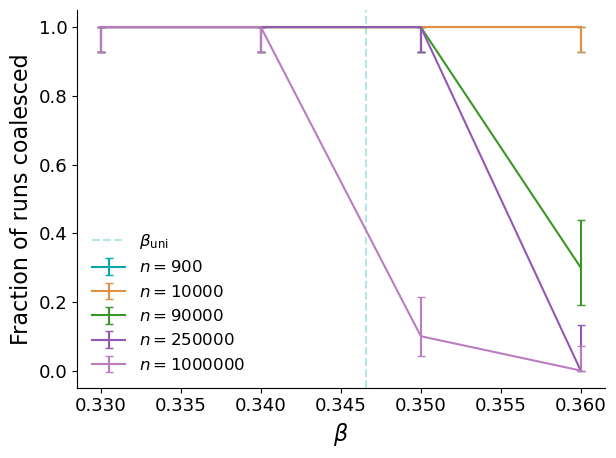

In [61]:
fig, ax = plt.subplots()

for N in sorted(df_filtered['N'].unique()):
    sub_df = df_filtered[df_filtered['N'] == N].sort_values('beta')
    k = sub_df['n_coal'].values
    n = sub_df['n_runs'].values
    p, err_down, err_up = wilson_interval(k, n)
    if graph_type == 'EA2D' or graph_type == 'F2D':
        ax.errorbar(sub_df['beta'], p, yerr=[err_down, err_up],label=rf'$n={N**2}$', capsize=3)
    elif graph_type == 'EA3D' or graph_type == 'F3D':
        ax.errorbar(sub_df['beta'], p, yerr=[err_down, err_up],label=rf'$n={N**3}$', capsize=3)
    else:
        ax.errorbar(sub_df['beta'], p, yerr=[err_down, err_up],label=rf'$n={N}$', capsize=3)
ax.axvline(beta_uni, linestyle='--', alpha=0.3, label=rf'$\beta_\mathrm{{uni}}$')
ax.set_xlabel(rf'$\beta$')
ax.set_ylabel('Fraction of runs coalesced')
ax.legend()
plt.tight_layout()
plt.show()

In [62]:
fig.savefig(f'../results/{folder_data}/coal_frac_{graph_type}_{coup_type}_d{d}.pdf', bbox_inches='tight')

# Scaling of coalescence times

In [70]:
max_iter_plot = 10**9
if graph_type == 'ER' and coup_type == 'gauss':
    beta_plot = [0.2,0.27,0.28,0.29,0.3,0.31,0.32] # beta selection for plotting
elif graph_type == 'ER' and coup_type == 'ising':
    beta_plot = [0.23,0.24,0.25] # beta selection for plotting
elif graph_type == 'EA2D' and coup_type == 'ising':
    beta_plot = df['beta'].unique() #[0.33,0.34] # beta selection for plotting
else:
    beta_plot = df['beta'].unique()

mask = (
    (df['n_coal'] == df['n_runs']) & # plot only beta values for which every run has coalesced (for unbiased averages)
    (df['beta'].isin(beta_plot)) &
    (df['max_iter'] == max_iter_plot) 
)
df_filtered = df[mask]
df_filtered

,beta,sampler,lazy,init_mode,n_runs,max_iter,N,n_coal,mean_coal_time,std_coal_time
0,0.35,F_beta_Glauber,False,full_star,50,1000000000,30,50,2.657374e+05,1.241649e+05
1,0.35,F_beta_Glauber,False,full_star,50,1000000000,100,50,5.879970e+06,1.652631e+06
2,0.35,F_beta_Glauber,False,full_star,50,1000000000,300,50,8.108316e+07,1.508847e+07
3,0.35,F_beta_Glauber,False,full_star,50,1000000000,500,50,2.575589e+08,4.688240e+07
5,0.35,F_beta_Glauber,False,full_star,50,1000000000,10,50,1.045354e+04,5.865958e+03
6,0.35,F_beta_Glauber,False,full_star,50,1000000000,20,50,9.427674e+04,4.897509e+04
7,0.35,F_beta_Glauber,False,full_star,50,1000000000,60,50,1.688840e+06,5.266936e+05
8,0.35,F_beta_Glauber,False,full_star,50,1000000000,200,50,2.996647e+07,5.203845e+06
9,0.36,F_beta_Glauber,False,full_star,50,1000000000,30,50,1.055441e+06,6.161785e+05
10,0.36,F_beta_Glauber,False,full_star,50,1000000000,100,50,5.870943e+07,3.824929e+07


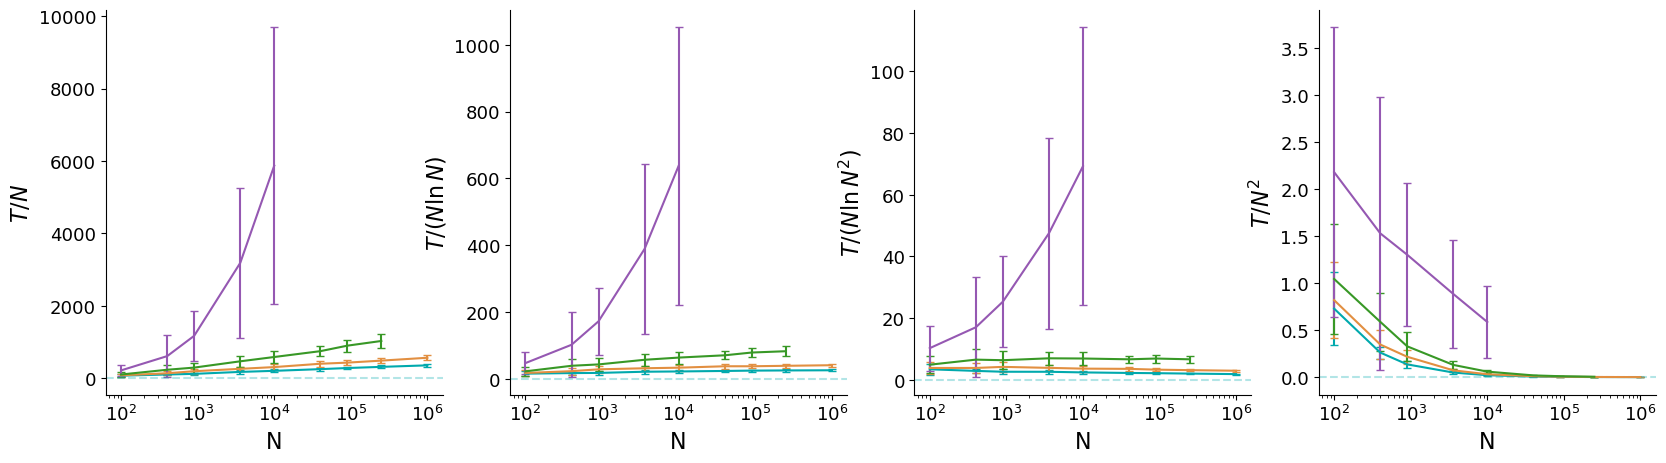

In [71]:
fig, axes = plt.subplots(1, 4, figsize=(20, 5))
scalings = {
    r'$T / N$': (lambda N, T: T / N, 
                lambda N, T, sT: sT / N),
    r'$T / (N \ln N)$': (lambda N, T: T / (N * np.log(N)), 
                          lambda N, T, sT: sT / (N * np.log(N))),
    r'$T / (N \ln N^2)$': (lambda N, T: T / (N * np.log(N)**2), 
                          lambda N, T, sT: sT / (N * np.log(N)**2)),
    r'$T / N^2$': (lambda N, T: T / N**2, 
                   lambda N, T, sT: sT / N**2),
}
for ax, (label, (scaling_fn, err_fn)) in zip(axes, scalings.items()):
    for beta in sorted(df_filtered['beta'].unique()):
        sub_df = df_filtered[df_filtered['beta'] == beta].sort_values('N')
        N = sub_df['N'].values
        if graph_type in ('EA2D', 'F2D'):
            N = N**2
        if graph_type in ('EA3D', 'F3D'):
            N = N**3
        T = sub_df['mean_coal_time'].values
        sT = sub_df['std_coal_time'].values
        ax.errorbar(N, scaling_fn(N, T), yerr=err_fn(N, T, sT), label=f'beta={beta:.3f}', capsize=3)
    ax.axhline(0, linestyle='--', alpha=0.3)
    ax.set_xlabel('N')
    ax.set_ylabel(label)
    ax.set_xscale('log')   
plt.show()

beta=0.330 [NlnN]: A1=31.0038 ± 0.9478, B1=-76.4805 ± 7.3021, R²=0.9400
beta=0.330 [N**D]:  C=37.7653 ± 4.2582, D=1.1731 ± 0.0117, R²=0.9993
beta=0.330 [N(lnN)²]: A2=1.2661 ± 0.0838, B2=10.0379 ± 0.6454, R²=0.9719

beta=0.340 [NlnN]: A1=52.4372 ± 0.9626, B1=-164.6650 ± 7.4162, R²=0.9860
beta=0.340 [N**D]:  C=43.2674 ± 8.0031, D=1.2000 ± 0.0191, R²=0.9982
beta=0.340 [N(lnN)²]: A2=2.8557 ± 0.2809, B2=6.2327 ± 2.1641, R²=0.5423



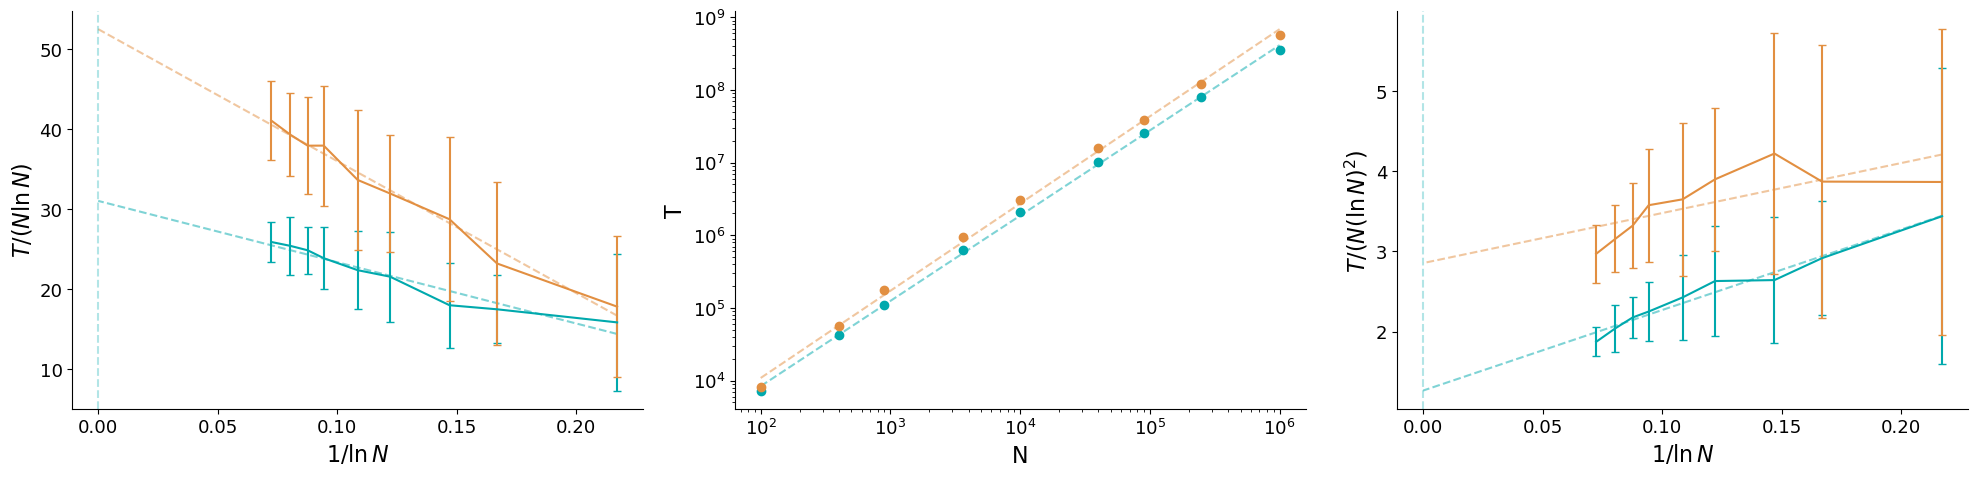

In [66]:
fig, axes = plt.subplots(1, 3, figsize=(20, 5))
fit_coeffs = {}

for beta in sorted(df_filtered['beta'].unique()):
    sub_df = df_filtered[df_filtered['beta'] == beta].sort_values('N')
    N = sub_df['N'].values
    if graph_type in ('EA2D', 'F2D'):
        N = N**2
    if graph_type in ('EA3D', 'F3D'):
        N = N**3
    T = sub_df['mean_coal_time'].values
    sT = sub_df['std_coal_time'].values

    # --- plot 1: T/(NlnN) vs 1/lnN ---
    x = 1 / np.log(N)
    y = T / (N * np.log(N))
    yerr = sT / (N * np.log(N))
    eb = axes[0].errorbar(x, y, yerr=yerr, label=f'beta={beta:.3f}', capsize=3)
    color = eb.lines[0].get_color() # reuse same color for fit line
    res1 = linregress(x, y)  # slope=B1, intercept=A1
    x_fit = np.linspace(x.max(), 0, 100)
    axes[0].plot(x_fit, res1.slope * x_fit + res1.intercept, linestyle='--', alpha=0.5, color=color)
    print(f"beta={beta:.3f} [NlnN]: A1={res1.intercept:.4f} ± {res1.intercept_stderr:.4f}, "
          f"B1={res1.slope:.4f} ± {res1.stderr:.4f}, R²={res1.rvalue**2:.4f}")

    # --- plot 2: log T vs log N ---
    res2 = linregress(np.log(N), np.log(T))
    D = res2.slope
    C = np.exp(res2.intercept)
    C_err = C * res2.intercept_stderr
    axes[1].loglog(N, T, 'o', color=color, label=f'beta={beta:.3f} (D={D:.3f})')
    axes[1].loglog(N, C * N**D, '--', alpha=0.5, color=color)
    print(f"beta={beta:.3f} [N**D]:  C={C:.4f} ± {C_err:.4f}, "
          f"D={D:.4f} ± {res2.stderr:.4f}, R²={res2.rvalue**2:.4f}")

    # --- plot 3: T/(N(lnN)^2) vs 1/lnN ---
    y3 = T / (N * np.log(N)**2)
    yerr3 = sT / (N * np.log(N)**2)
    axes[2].errorbar(x, y3, yerr=yerr3, capsize=3, color=color, label=f'beta={beta:.3f}')
    res3 = linregress(x, y3)  # intercept=A2, slope=B2
    axes[2].plot(x_fit, res3.slope * x_fit + res3.intercept, linestyle='--', alpha=0.5, color=color)
    print(f"beta={beta:.3f} [N(lnN)²]: A2={res3.intercept:.4f} ± {res3.intercept_stderr:.4f}, "
        f"B2={res3.slope:.4f} ± {res3.stderr:.4f}, R²={res3.rvalue**2:.4f}\n")

    fit_coeffs[beta] = {
        # NlnN fit 
        'A1': res1.intercept, 'A1_err': res1.intercept_stderr,
        'B1': res1.slope,     'B1_err': res1.stderr,
        'r2_NlnN': res1.rvalue**2,
        # power law fit
        'C': C,               'C_err': C_err,
        'D': D,               'D_err': res2.stderr,
        'r2_powerlaw': res2.rvalue**2,
        'A2': res3.intercept, 'A2_err': res3.intercept_stderr,
        'B2': res3.slope,     'B2_err': res3.stderr,
        'r2_NlnN2': res3.rvalue**2,
    }

axes[0].axvline(0, linestyle='--', alpha=0.3)
axes[0].set_xlabel(r'$1 / \ln N$')
axes[0].set_ylabel(r'$T / (N \ln N)$')

axes[1].set_xlabel('N')
axes[1].set_ylabel('T')

axes[2].axvline(0, linestyle='--', alpha=0.3)
axes[2].set_xlabel(r'$1 / \ln N$')
axes[2].set_ylabel(r'$T / (N (\ln N)^2)$')

plt.tight_layout()
plt.show()

beta_sel= 0.34


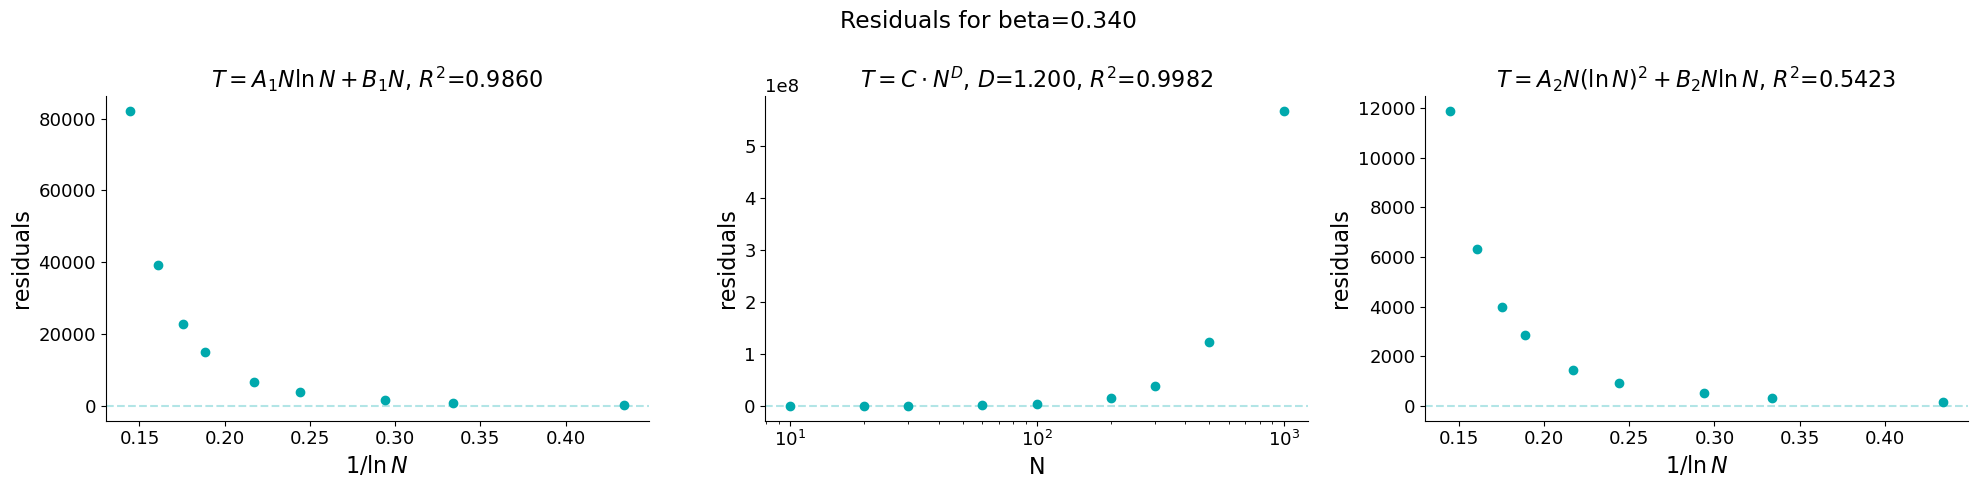

In [67]:
if graph_type == 'ER' and coup_type == 'gauss':
    beta_sel = 0.32
elif graph_type == 'ER' and coup_type == 'ising':
    beta_sel = 0.24
elif graph_type == 'EA2D' and coup_type == 'ising':
    beta_sel = 0.34
else:
    beta_sel = df['beta'].unique()[0]

print("beta_sel=", beta_sel)
sub_df = df_filtered[df_filtered['beta'] == beta_sel].sort_values('N')
N = sub_df['N'].values
T = sub_df['mean_coal_time'].values

x = 1 / np.log(N)
y = T / (N * np.log(N))

fc = fit_coeffs[beta_sel]

fig, axes = plt.subplots(1, 3, figsize=(20, 5))

# --- residuals of NlnN fit ---
y_pred1 = fc['A1'] + fc['B1'] * x
residuals1 = y - y_pred1
axes[0].axhline(0, linestyle='--', alpha=0.3)
axes[0].plot(x, residuals1, 'o')
axes[0].set_xlabel(r'$1 / \ln N$')
axes[0].set_ylabel('residuals')
axes[0].set_title(rf"$T = A_1 N\ln N + B_1 N$, $R^2$={fc['r2_NlnN']:.4f}")

# --- residuals of power law fit ---
y_pred2 = fc['C'] * N**fc['D']
residuals2 = T - y_pred2
axes[1].axhline(0, linestyle='--', alpha=0.3)
axes[1].plot(N, residuals2, 'o')
axes[1].set_xscale('log')
axes[1].set_xlabel('N')
axes[1].set_ylabel('residuals')
axes[1].set_title(rf"$T = C \cdot N^D$, $D$={fc['D']:.3f}, $R^2$={fc['r2_powerlaw']:.4f}")

# --- residuals of N(lnN)^2 fit ---
y3 = T / (N * np.log(N)**2)
y_pred3 = fc['A2'] + fc['B2'] * x
residuals3 = y3 - y_pred3
axes[2].axhline(0, linestyle='--', alpha=0.3)
axes[2].plot(x, residuals3, 'o')
axes[2].set_xlabel(r'$1 / \ln N$')
axes[2].set_ylabel('residuals')
axes[2].set_title(rf"$T = A_2 N(\ln N)^2 + B_2 N\ln N$, $R^2$={fc['r2_NlnN2']:.4f}")

fig.suptitle(f'Residuals for beta={beta_sel:.3f}')
plt.tight_layout()
plt.show()

In [68]:
# R² of power law fit in linear space (comparable to NlnN R²)
y_pred_linear = fc['C'] * N**fc['D']
ss_res = np.sum((T - y_pred_linear)**2)
ss_tot = np.sum((T - np.mean(T))**2)
r2_powerlaw_linear = 1 - ss_res / ss_tot
print(f"Power law R² in linear space: {r2_powerlaw_linear:.4f}")

Power law R² in linear space: -0.2246


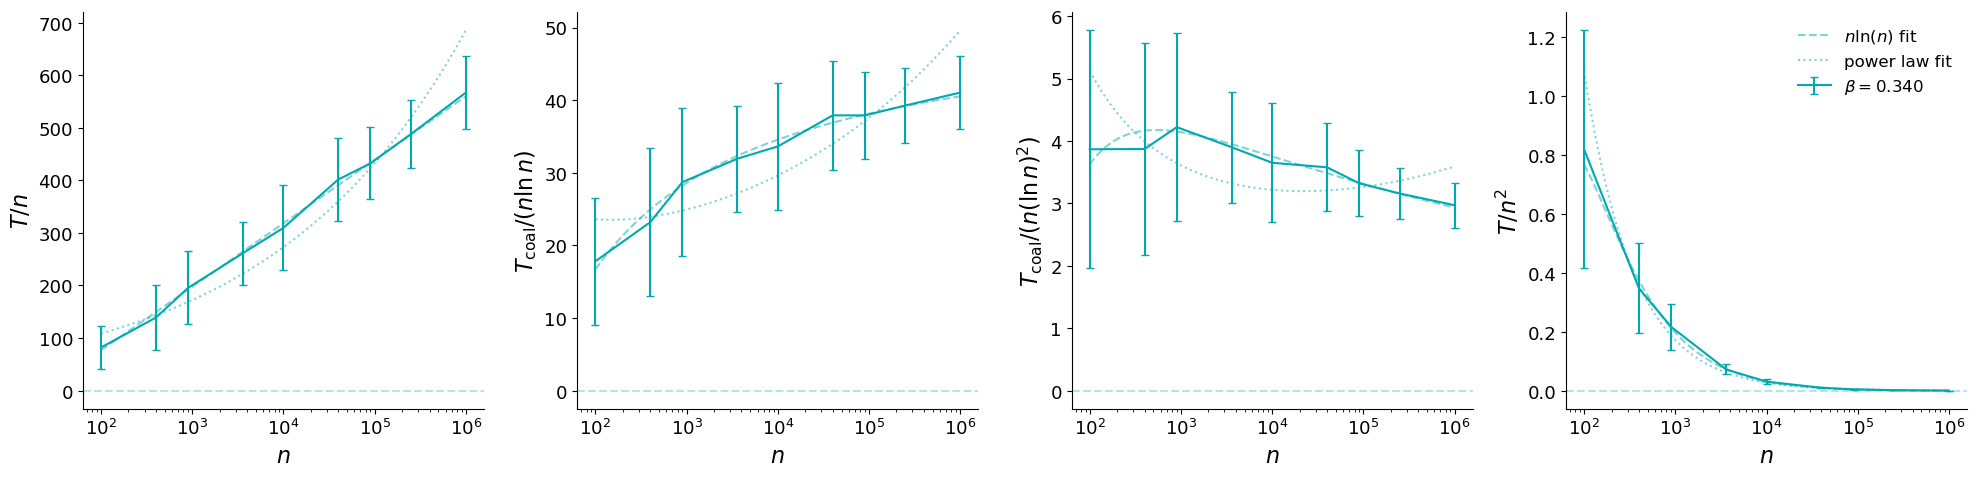

In [69]:
fig, axes = plt.subplots(1, 4, figsize=(20, 5))
#fig, axes = plt.subplots(1, 2, figsize=(10, 5))
scalings = {
    r'$T / n$': (lambda N, T: T / N,
                 lambda N, T, sT: sT / N),
    rf'$T_\mathrm{{coal}} / (n \ln n)$': (lambda N, T: T / (N * np.log(N)),
                          lambda N, T, sT: sT / (N * np.log(N))),
    rf'$T_\mathrm{{coal}} / (n (\ln n)^2)$': (lambda N, T: T / (N * np.log(N)**2),
                            lambda N, T, sT: sT / (N * np.log(N)**2)),
    r'$T / n^2$': (lambda N, T: T / N**2,
                   lambda N, T, sT: sT / N**2),
}

N_fit = np.logspace(np.log10(100), np.log10(1e6), 300)  # smooth curve for fit

for ax, (label, (scaling_fn, err_fn)) in zip(axes, scalings.items()):
    for beta in [beta_sel]: #sorted(df_filtered['beta'].unique()):
        sub_df = df_filtered[df_filtered['beta'] == beta].sort_values('N')
        N = sub_df['N'].values
        if graph_type in ('EA2D', 'F2D'):
            N = N**2
        if graph_type in ('EA3D', 'F3D'):
            N = N**3
        T = sub_df['mean_coal_time'].values
        sT = sub_df['std_coal_time'].values

        eb = ax.errorbar(N, scaling_fn(N, T), yerr=err_fn(N, T, sT),
                         label=rf'$\beta={beta:.3f}$', capsize=3)
        color = eb.lines[0].get_color()

        fc = fit_coeffs[beta]

        # NlnN fit: T = A1*N*lnN + B1*N, plot through each scaling
        T_NlnN = fc['A1'] * N_fit * np.log(N_fit) + fc['B1'] * N_fit
        ax.plot(N_fit, scaling_fn(N_fit, T_NlnN), '--', color=color, alpha=0.5, label=rf'$n\ln(n)$ fit')

        # power law fit: T = C * N**D
        T_power = fc['C'] * N_fit**fc['D']
        ax.plot(N_fit, scaling_fn(N_fit, T_power), ':', color=color, alpha=0.5, label=f'power law fit')

        # N(lnN)^2 fit: T = A2*N*(lnN)^2 + B2*N*lnN
        T_NlnN2 = fc['A2'] * N_fit * np.log(N_fit)**2 + fc['B2'] * N_fit * np.log(N_fit)
#        ax.plot(N_fit, scaling_fn(N_fit, T_NlnN2), '-.', color=color, alpha=0.5, label=r'$N(\ln N)^2$ fit')

    ax.axhline(0, linestyle='--', alpha=0.3)
    ax.set_xlabel(rf'$n$')
    ax.set_ylabel(label)
    ax.set_xscale('log')

# single legend on last ax
handles, labels = axes[0].get_legend_handles_labels()
axes[3].legend()
plt.tight_layout()
plt.show()

In [51]:
fig.savefig(f'../results/{folder_data}/coal_scaling_{graph_type}_{coup_type}_d{d}_beta{beta_sel:.3f}.pdf', bbox_inches='tight')

In [ ]:
K=30
Q=-100
delta = 1.21
aa = 3
cc=1
def f(n,K,Q): 
    return K*n*np.log(n)+Q*n
def f2(n,K,Q): 
    return K*n*np.log(n)**2+Q*n*np.log(n)
def g(n,aa, delta, cc): 
    return aa*(n**delta) + cc*n
nr = np.arange(100,10**6,10)
plt.plot(nr,f(nr,K,Q)/(nr*np.log(nr)) )
plt.plot(nr,f2(nr,2,2)/(nr*np.log(nr)) )
plt.plot(nr,g(nr,aa,delta,cc)/(nr*np.log(nr)) )

#plt.plot(nr,f(nr,K,Q)/(nr*(np.log(nr)**2)) )
#plt.plot(nr,f2(nr,2,2)/(nr*(np.log(nr)**2)) )
#plt.plot(nr,g(nr,aa,delta,cc)/(nr*(np.log(nr)**2)) )

#plt.plot(nr,f(nr,K,Q)/(nr**2))
#plt.plot(nr,f2(nr,2,2)/(nr**2))
#plt.plot(nr,g(nr,aa,delta,cc)/(nr**2))

plt.xscale('log')